```markdown
# Projet d'Évaluation : Apprentissage Supervisé (Partie B)

Ce notebook est structuré en suivant les consignes du document de cadrage de la **Partie B** et applique la méthodologie de modélisation vue dans le notebook de TP (`Tp_ML (1).ipynb`).

## Plan de route :
1. **Exploration et Visualisation des Données** (déjà entamée avec l'analyse descriptive et les premiers graphiques).
2. **Modélisation de la Régression Logistique** (Simple & Multiple).
3. **Analyse Discriminante Linéaire (LDA)** & Analyse des seuils de décision (50%, 20%).
4. **Évaluation et Comparaison des Modèles** : Calcul des matrices de confusion, taux d'erreur globale, faux positifs et faux négatifs.
```

In [79]:
# Lecture du fichier de consignes de la Partie B
try:
    with open('/content/CC_Partie_B_ML_Finance_S7_G2- V2.md', 'r', encoding='utf-8') as f:
        consignes = f.read()
    print("=== EXTRAIT DES CONSIGNES (PARTIE B) ===")
    print("\n".join(consignes.splitlines()[:40]))  # Affiche les 40 premières lignes
except Exception as e:
    print("Erreur lors de la lecture des consignes :", e)

=== EXTRAIT DES CONSIGNES (PARTIE B) ===
# Contrôle continu — Partie B · Machine Learning appliqué à la finance

![Évaluation individuelle](https://img.shields.io/badge/Modalit%C3%A9-Individuelle-2563eb) ![Durée : 2 h](https://img.shields.io/badge/Dur%C3%A9e-2%20heures-0d9488) ![S7 ENCG Settat](https://img.shields.io/badge/ENCG%20Settat-S7-7c3aed) ![Note 30 %](https://img.shields.io/badge/Pond%C3%A9ration-30%25-c2410c)

> **S7 FIN et CI · Module BD & DS · Année universitaire 2026–2027**  
> **Travail individuel obligatoire sur machine.** Chaque étudiant traite **son sujet déjà attribué** et choisit **un algorithme principal parmi les 29 étudiés**.  
> **Durée du TP : 2 heures.** Soutenance individuelle **de 8 minutes lors de la séance suivante**. Une **vidéo explicative courte** fait partie des livrables.

## 1. Objectif du travail

À partir d'un **jeu de données financier réel**, mener une démarche reproductible de science des données : problématique → données → exploration → préparat

In [81]:
# Inspection complète de toutes les en-têtes Markdown du notebook TP_ML (1).ipynb
import json
try:
    with open('/content/Tp_ML (1).ipynb', 'r', encoding='utf-8') as f:
        tp_data = json.load(f)

    print("=== TITRES ET EN-TÊTES DU NOTEBOOK TP_ML ===")
    for i, cell in enumerate(tp_data.get('cells', [])):
        if cell.get('cell_type') == 'markdown':
            content = "".join(cell.get('source', []))
            # Afficher les lignes commençant par des '#' pour avoir la structure/plan
            headers = [line for line in content.splitlines() if line.strip().startswith('#')]
            if headers:
                print(f"Cellule {i:3d} : {headers[0]}")
except Exception as e:
    print("Erreur lors de l'analyse du plan du notebook TP :", e)

=== TITRES ET EN-TÊTES DU NOTEBOOK TP_ML ===
Cellule   0 : # Partie B — Exploration de 29 algorithmes de Machine Learning
Cellule   4 : ## 1. Régression linéaire
Cellule   6 : ## 2. Ridge
Cellule   8 : ## 3. Lasso
Cellule  10 : ## 4. Régression polynomiale
Cellule  12 : ## 5. Arbre de régression
Cellule  14 : ## 6. Forêt aléatoire — régression
Cellule  16 : ## 7. Gradient Boosting — régression
Cellule  18 : ## 8. Régression logistique
Cellule  20 : ## 9. KNN
Cellule  22 : ## 10. Naive Bayes
Cellule  24 : ## 11. Arbre de décision
Cellule  26 : ## 12. Forêt aléatoire — classification
Cellule  28 : ## 13. SVM
Cellule  30 : ## 14. Gradient Boosting — classification
Cellule  32 : ## 15. AdaBoost
Cellule  34 : ## 16. XGBoost
Cellule  36 : ## 17. K-means
Cellule  38 : ## 18. Classification hiérarchique
Cellule  40 : ## 19. DBSCAN
Cellule  42 : ## 20. Mélanges gaussiens
Cellule  44 : ## 21. ACP
Cellule  46 : ## 22. t-SNE
Cellule  48 : ## 23. UMAP
Cellule  50 : ## 24. Isolation Forest
Cellule  

In [82]:
# Extraction du code de la section '8. Régression logistique' du notebook de TP
try:
    # Recherche de la cellule contenant '## 8. Régression logistique' et des cellules de code qui la suivent
    idx_start = None
    idx_end = None
    for idx, cell in enumerate(tp_data.get('cells', [])):
        if cell.get('cell_type') == 'markdown':
            content = "".join(cell.get('source', []))
            if "## 8. Régression logistique" in content:
                idx_start = idx
            elif idx_start is not None and ("## 9." in content or "## " in content):
                idx_end = idx
                break

    if idx_start is not None:
        if idx_end is None: idx_end = idx_start + 10
        print(f"=== ALGORITHME DE RÉFÉRENCE (TP) - SECTION REGRESSION LOGISTIQUE (Cellules {idx_start} à {idx_end}) ===\n")
        for j in range(idx_start, idx_end):
            cell = tp_data['cells'][j]
            cell_type = cell.get('cell_type')
            source = "".join(cell.get('source', []))
            print(f"[{cell_type.upper()} CELL {j}]:")
            print(source)
            print("-" * 50)
    else:
        print("La section '8. Régression logistique' n'a pas été trouvée de manière automatique.")
except Exception as e:
    print("Erreur lors de l'extraction de la section du TP :", e)

=== ALGORITHME DE RÉFÉRENCE (TP) - SECTION REGRESSION LOGISTIQUE (Cellules 18 à 20) ===

[MARKDOWN CELL 18]:
## 8. Régression logistique

**Question ciblée (Partie B) :** Comment interpréter une probabilité prédite et ajuster le seuil de classification ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.
--------------------------------------------------
[CODE CELL 19]:
from sklearn.linear_model import LogisticRegression
modele=make_pipeline(StandardScaler(),LogisticRegression(C=.2,max_iter=1500,random_state=GRAINE)).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))
--------------------------------------------------


```markdown
## Application de la méthodologie du TP sur les données financières

Nous allons :
1. Définir la graine aléatoire pour garantir la reproductibilité.
2. Diviser le jeu de données en ensemble d'entraînement (80%) et ensemble de test (20%).
3. Construire le pipeline Scikit-Learn contenant la mise à l'échelle (`StandardScaler`) et le classifieur `LogisticRegression`.
4. Évaluer le modèle avec le score F1, le score d'exactitude (Accuracy) et tracer la matrice de confusion.
```

In [84]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report, confusion_matrix

# Fixer la graine aléatoire pour la reproductibilité
GRAINE = 42

# Définition des variables explicatives (X) et de la variable cible (y)
X_data = ccdef[['balance', 'income', 'student2']]
y_data = ccdef['default2']

# Séparation en ensemble d'entraînement et de test (sans fuite de données)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_data, y_data, test_size=0.2, random_state=GRAINE, stratify=y_data)

# Création et entraînement du pipeline selon la structure du TP
modele = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=0.2, max_iter=1500, random_state=GRAINE)
)

modele.fit(Xc_ent, yc_ent)

# Prédictions et évaluation
y_pred = modele.predict(Xc_test)
f1 = f1_score(yc_test, y_pred)

print("=== ÉVALUATION DU MODÈLE DE RÉGRESSION LOGISTIQUE ===")
print(f"Score F1 sur le jeu de test : {f1:.6f}")
print("\nRapport de classification complet :\n")
print(classification_report(yc_test, y_pred, target_names=['No Default', 'Default']))

=== ÉVALUATION DU MODÈLE DE RÉGRESSION LOGISTIQUE ===
Score F1 sur le jeu de test : 0.437500

Rapport de classification complet :

              precision    recall  f1-score   support

  No Default       0.98      1.00      0.99      1933
     Default       0.72      0.31      0.44        67

    accuracy                           0.97      2000
   macro avg       0.85      0.65      0.71      2000
weighted avg       0.97      0.97      0.97      2000



```markdown
## Analyse Discriminante Linéaire (LDA) - Méthodologie du TP

Nous allons maintenant entraîner un modèle LDA sur le même découpage d'entraînement (`Xc_ent`) et évaluer sa performance sur le jeu de test (`Xc_test`) pour assurer une comparaison équitable.
```

In [85]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Création et entraînement du pipeline LDA avec StandardScaler
modele_lda = make_pipeline(
    StandardScaler(),
    LinearDiscriminantAnalysis()
)

modele_lda.fit(Xc_ent, yc_ent)

# Prédictions et évaluation
y_pred_lda = modele_lda.predict(Xc_test)
f1_lda = f1_score(yc_test, y_pred_lda)

print("=== ÉVALUATION DU MODÈLE LDA ===")
print(f"Score F1 de la LDA sur le jeu de test : {f1_lda:.6f}")
print("\nRapport de classification complet (LDA) :\n")
print(classification_report(yc_test, y_pred_lda, target_names=['No Default', 'Default']))

=== ÉVALUATION DU MODÈLE LDA ===
Score F1 de la LDA sur le jeu de test : 0.363636

Rapport de classification complet (LDA) :

              precision    recall  f1-score   support

  No Default       0.97      1.00      0.99      1933
     Default       0.76      0.24      0.36        67

    accuracy                           0.97      2000
   macro avg       0.87      0.62      0.67      2000
weighted avg       0.97      0.97      0.96      2000



```markdown
## Analyse Comparative et Variation des Seuils (50% vs 20%)

En finance et gestion des risques de crédit, le coût d'un faux négatif (ne pas détecter un client en défaut) est souvent bien supérieur à celui d'un faux positif. Nous allons comparer les performances de nos modèles sous deux seuils de décision : **50% (seuil standard)** et **20% (seuil plus conservateur)**.
```

In [86]:
# Obtention des probabilités prédites sur le jeu de test
y_prob_lr = modele.predict_proba(Xc_test)[:, 1]
y_prob_lda = modele_lda.predict_proba(Xc_test)[:, 1]

# Seuils à comparer
seuils = [0.5, 0.2]

for seuil in seuils:
    print(f"\n================ SEUIL DE DÉCISION : {seuil*100:.0f}% ================")

    # Application du seuil pour la Régression Logistique
    y_pred_lr_seuil = (y_prob_lr >= seuil).astype(int)
    cm_lr = confusion_matrix(yc_test, y_pred_lr_seuil)

    # Application du seuil pour la LDA
    y_pred_lda_seuil = (y_prob_lda >= seuil).astype(int)
    cm_lda = confusion_matrix(yc_test, y_pred_lda_seuil)

    print(f"\n[Régression Logistique - Seuil {seuil}] :")
    print(f"Score F1 : {f1_score(yc_test, y_pred_lr_seuil):.6f}")
    print("Matrice de confusion :")
    print(f"  [VN={cm_lr[0,0]}  FP={cm_lr[0,1]}]")
    print(f"  [FN={cm_lr[1,0]}  FP={cm_lr[1,1]}]")
    print(f"Faux Négatifs (Défauts non détectés) : {cm_lr[1,0]} / {yc_test.sum()}")

    print(f"\n[LDA - Seuil {seuil}] :")
    print(f"Score F1 : {f1_score(yc_test, y_pred_lda_seuil):.6f}")
    print("Matrice de confusion :")
    print(f"  [VN={cm_lda[0,0]}  FP={cm_lda[0,1]}]")
    print(f"  [FN={cm_lda[1,0]}  FP={cm_lda[1,1]}]")
    print(f"Faux Négatifs (Défauts non détectés) : {cm_lda[1,0]} / {yc_test.sum()}")


================ SEUIL DE DÉCISION : 50% ================

[Régression Logistique - Seuil 0.5] :
Score F1 : 0.437500
Matrice de confusion :
  [VN=1925  FP=8]
  [FN=46  FP=21]
Faux Négatifs (Défauts non détectés) : 46 / 67

[LDA - Seuil 0.5] :
Score F1 : 0.363636
Matrice de confusion :
  [VN=1928  FP=5]
  [FN=51  FP=16]
Faux Négatifs (Défauts non détectés) : 51 / 67

================ SEUIL DE DÉCISION : 20% ================

[Régression Logistique - Seuil 0.2] :
Score F1 : 0.465116
Matrice de confusion :
  [VN=1868  FP=65]
  [FN=27  FP=40]
Faux Négatifs (Défauts non détectés) : 27 / 67

[LDA - Seuil 0.2] :
Score F1 : 0.476190
Matrice de confusion :
  [VN=1872  FP=61]
  [FN=27  FP=40]
Faux Négatifs (Défauts non détectés) : 27 / 67


In [47]:
# importing important liberaries
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('seaborn-v0_8-white')

In [48]:
pip install xlrd

In [49]:
pip install openpyxl

In [50]:
# LOading the dataa
ccdef = pd.read_excel('/content/drive/MyDrive/cc partie B Fin2/Default.xlsx')
ccdef

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,Unnamed: 0,default,student,balance,income
0,1,No,No,729.526495,44361.625074
1,2,No,Yes,817.180407,12106.134700
2,3,No,No,1073.549164,31767.138947
3,4,No,No,529.250605,35704.493935
4,5,No,No,785.655883,38463.495879
...,...,...,...,...,...
9995,9996,No,No,711.555020,52992.378914
9996,9997,No,No,757.962918,19660.721768
9997,9998,No,No,845.411989,58636.156984
9998,9999,No,No,1569.009053,36669.112365


In [51]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [52]:
ccdef.shape

(10000, 5)

In [53]:
ccdef.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  10000 non-null  int64  
 1   default     10000 non-null  object 
 2   student     10000 non-null  object 
 3   balance     10000 non-null  float64
 4   income      10000 non-null  float64
dtypes: float64(2), int64(1), object(2)
memory usage: 390.8+ KB


In [54]:
#checking NUll values
ccdef.isnull().sum()

,0
Unnamed: 0,0
default,0
student,0
balance,0
income,0


In [55]:
# Summarizing data
ccdef.describe()

,Unnamed: 0,balance,income
count,10000.00000,10000.000000,10000.000000
mean,5000.50000,835.374886,33516.981876
std,2886.89568,483.714985,13336.639563
min,1.00000,0.000000,771.967729
25%,2500.75000,481.731105,21340.462903
50%,5000.50000,823.636973,34552.644802
75%,7500.25000,1166.308386,43807.729272
max,10000.00000,2654.322576,73554.233495


In [56]:
# Analysis of Zero Values in Predictors
(ccdef.balance == 0).sum(axis=0)

np.int64(499)

student
No     7056
Yes    2944
Name: count, dtype: int64


/tmp/ipykernel_1161/3350707780.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="student", data=ccdef, palette='magma');


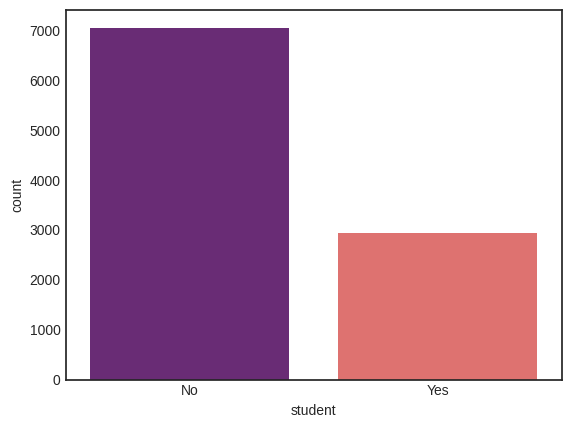

In [57]:
#Categorical Variable Analysis
print(ccdef.student.value_counts())
sns.countplot(x="student", data=ccdef, palette='magma');

default
No     9667
Yes     333
Name: count, dtype: int64


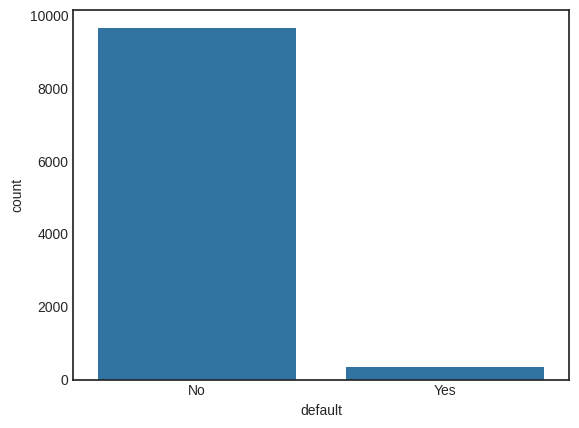

In [58]:
#Response Variable Analysis
print(ccdef.default.value_counts())
sns.countplot(x = 'default', data = ccdef);

***Encode Categorical Variables***

In [59]:
ccdef['default2'] = ccdef.default.factorize()[0]
ccdef['student2'] = ccdef.student.factorize()[0]

ccdef.head()

,Unnamed: 0,default,student,balance,income,default2,student2
0,1,No,No,729.526495,44361.625074,0,0
1,2,No,Yes,817.180407,12106.134700,0,1
2,3,No,No,1073.549164,31767.138947,0,0
3,4,No,No,529.250605,35704.493935,0,0
4,5,No,No,785.655883,38463.495879,0,0


# Logistic Regression - Sklearn

In [60]:
# training and testing data
X_train = ccdef.balance.values.reshape(-1,1)

y = ccdef.default2

X_test = np.arange(ccdef.balance.min(), ccdef.balance.max()).reshape(-1 ,1)

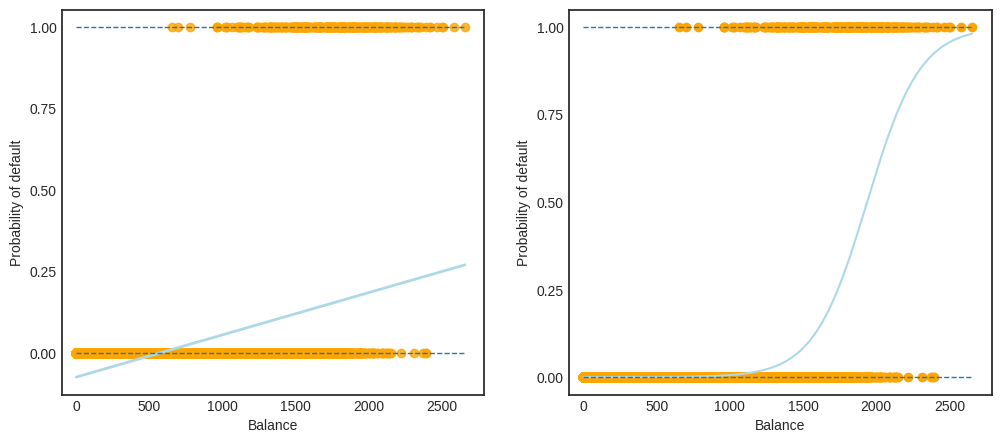

In [61]:
#Calculate probability using logistic regression
import sklearn.linear_model as skl_lm

clf = skl_lm.LogisticRegression(solver='newton-cg')
clf.fit(X_train,y)
prob = clf.predict_proba(X_test)

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(12,5))
sns.regplot(x=ccdef.balance, y=ccdef.default2, order=1, ci=None,scatter_kws={'color':'orange'},line_kws={'color':'lightblue', 'lw':2}, ax=ax1)

ax2.scatter(X_train, y, color='orange')
ax2.plot(X_test, prob[:,1], color='lightblue')
for ax in fig.axes:
    ax.hlines(1, xmin=ax.xaxis.get_data_interval()[0],xmax=ax.xaxis.get_data_interval()[1], linestyles='dashed', lw=1)
    ax.hlines(0, xmin=ax.xaxis.get_data_interval()[0],xmax=ax.xaxis.get_data_interval()[1], linestyles='dashed', lw=1)
    ax.set_ylabel('Probability of default')
    ax.set_xlabel('Balance')
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.])
    ax.set_xlim(xmin=-100)

In [62]:
 # Printing Cofficient and array of diatinct class
 print(clf)
 print('classes: ',clf.classes_)
 print('coefficients: ',clf.coef_)
 print('intercept :', clf.intercept_)

LogisticRegression(solver='newton-cg')
classes:  [0 1]
coefficients:  [[0.00549808]]
intercept : [-10.64992735]


***Logistic Regression Statsmodel***

In [63]:
import statsmodels.api as sm
import statsmodels.discrete.discrete_model as sms

pd.set_option('display.precision', 6)

X_train = sm.add_constant(ccdef.balance)

est = sm.Logit(y.ravel(), X_train).fit()

Optimization terminated successfully.
         Current function value: 0.079823
         Iterations 10


/tmp/ipykernel_1161/2002936506.py:8: FutureWarning: Series.ravel is deprecated. The underlying array is already 1D, so ravel is not necessary.  Use `to_numpy()` for conversion to a numpy array instead.
  est = sm.Logit(y.ravel(), X_train).fit()


In [64]:
est.summary2().tables[1]

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
const,-10.651331,0.361169,-29.491287,3.723665e-191,-11.359208,-9.943453
balance,0.005499,0.000220,24.952404,2.010855e-137,0.005067,0.005931


***Logistic Regression - Dummy Variable***

In [65]:
X_train = sm.add_constant(ccdef.student2)

y = ccdef.default2

est = sms.Logit(y, X_train).fit()

Optimization terminated successfully.
         Current function value: 0.145434
         Iterations 7


In [66]:
print(est.summary().tables[1].as_text())

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -3.5041      0.071    -49.554      0.000      -3.643      -3.366
student2       0.4049      0.115      3.520      0.000       0.179       0.630


***Multiple Logistic Regression***

In [67]:
 X_train = sm.add_constant(ccdef[['balance', 'income', 'student2']])

 est = sms.Logit(y, X_train).fit()

Optimization terminated successfully.
         Current function value: 0.078577
         Iterations 10


In [68]:
print(est.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -10.8690      0.492    -22.079      0.000     -11.834      -9.904
balance        0.0057      0.000     24.737      0.000       0.005       0.006
income      3.033e-06    8.2e-06      0.370      0.712    -1.3e-05    1.91e-05
student2      -0.6468      0.236     -2.738      0.006      -1.110      -0.184


***Cofunding***

In [69]:
#Create balance and default vectors for students

X_train = ccdef[ccdef.student == 'Yes'].balance.values.reshape(-1,1)
y = ccdef[ccdef.student == 'Yes'].default2

In [70]:
#Create balance and default vectors for non- students

X_train2 = ccdef[ccdef.student == 'No'].balance.values.reshape(-1,1)

y2 = ccdef[ccdef.student == 'No'].default2

In [71]:
# Create test vector
X_test = np.arange(ccdef.balance.min(), ccdef.balance.max()).reshape(-1,1)

In [72]:
# Fit both dataset to Logistic Regression

clf = skl_lm.LogisticRegression(solver='newton-cg')

clf2 = skl_lm.LogisticRegression(solver='newton-cg')

clf.fit(X_train,y)

LogisticRegression(solver='newton-cg')

In [73]:
clf2.fit(X_train2,y2)

LogisticRegression(solver='newton-cg')

In [74]:
# Calculate Probabilities

prob = clf.predict_proba(X_test)

prob2 = clf2.predict_proba(X_test)

In [75]:
# Confusion Matrix
ccdef.groupby(['student','default']).size().unstack('default')

default,No,Yes
student,,
No,6850,206
Yes,2817,127


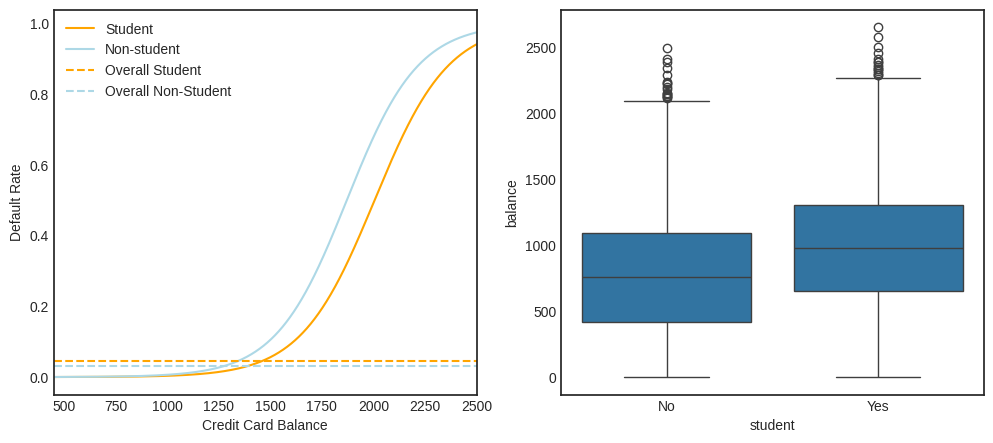

In [76]:
# Graphical Representation
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(12,5))

# Left plot
ax1.plot(X_test, prob[:,1], color='orange', label='Student')
ax1.plot(X_test, prob2[:,1], color='lightblue', label='Non-student')
ax1.hlines(127/2817, colors='orange', label='Overall Student',xmin=ax1.xaxis.get_data_interval()[0],xmax=ax1.xaxis.get_data_interval()[1], linestyles='dashed')
ax1.hlines(206/6850, colors='lightblue', label='Overall Non-Student',xmin=ax1.xaxis.get_data_interval()[0],xmax=ax1.xaxis.get_data_interval()[1], linestyles='dashed')
ax1.set_ylabel('Default Rate')
ax1.set_xlabel('Credit Card Balance')
ax1.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.])
ax1.set_xlim(450,2500)
ax1.legend(loc=2)

# Right plot
sns.boxplot(x='student', y='balance', data=ccdef, ax=ax2);

# Linear Discriminant Analysis

***50% Threshold***

In [77]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

X = ccdef[['balance', 'income', 'student2']]
y = ccdef.default2

lda = LinearDiscriminantAnalysis(solver='svd')

y_pred = lda.fit(X, y).predict(X)

ccdef_df = pd.DataFrame({'True default status': y, 'Predicted default status': y_pred})

ccdef_df.replace(to_replace={0:'No', 1:'Yes'}, inplace=True)

ccdef_df.groupby(['Predicted default status','True default status']).size().unstack('True default status')

True default status,No,Yes
Predicted default status,,
No,9645,254
Yes,22,79


*** 20% Threshold ***

In [78]:
decision_prob = 0.2
y_prob = lda.fit(X, y).predict_proba(X)

ccdef_df = pd.DataFrame({'True default status': y,'Predicted default status': y_prob[:,1] > decision_prob})

ccdef_df.replace(to_replace={0:'No', 1:'Yes', 'True':'Yes', 'False':'No'}, inplace=True)

ccdef_df.groupby(['Predicted default status','True default status']).size().unstack('True default status')

True default status,No,Yes
Predicted default status,,
False,9435,140
True,232,193
